# Studio Proyek 3: Fine-Tuning Transformer Pretrained untuk Klasifikasi Sentimen (SmSA)
Pembelajaran Mendalam (IF25-40401), Institut Teknologi Sumatera

**Cara pakai:** jalankan sel dari atas ke bawah. `MODE = "uji"` untuk cek cepat (1 backbone, 1 seed, 1 epoch),
`MODE = "penuh"` untuk matriks lengkap (27 run). Run yang sudah ada di CSV otomatis dilewati jika sesi terputus.

**Protokol evaluasi (sesuai lembar soal):** validasi dipakai HANYA untuk memilih epoch terbaik
(bobot epoch dengan F1 makro validasi tertinggi dipulihkan), dan data uji dievaluasi SEKALI per run.

In [1]:
RANCANGAN = {
    "dataset_dan_subset": (
        "SmSA (IndoNLU), 3 kelas: negatif/netral/positif. Dipilih karena teksnya Bahasa Indonesia "
        "sehingga IndoBERT bisa dipakai dan perbandingan backbone adil. Pakai pembagian resmi; "
        "subset latih 5.000 kalimat (stratified, seed tetap) agar 27 run muat di GPU T4 gratis; "
        "validasi dan uji (500 kalimat) dipakai penuh."
    ),
    "matriks": (
        "3 backbone (mBERT, DistilmBERT, IndoBERT) x 3 strategi (full FT, partial freezing, "
        "linear probing) x 3 seed (42, 123, 2026) = 27 run. Head diganti ke 3 label di semua run. "
        "Pembanding: baseline TF-IDF + Logistic Regression dan tebakan acak (F1 makro ~0,33)."
    ),
    "variabel_terkunci": (
        "max_length=128; batch_size=32; maksimum 3 epoch; AdamW weight_decay=0.01; warmup 10%; fp16; "
        "seed 42/123/2026; LR full=3e-5, partial=3e-5, probing=3e-3. Pemilihan epoch: bobot dengan "
        "F1 makro validasi tertinggi; data uji dievaluasi sekali per run."
    ),
    "H1": "IndoBERT memiliki F1 makro tertinggi karena pretraining khusus Bahasa Indonesia.",
    "H2": "DistilmBERT inferensinya ~1,5-2x lebih cepat dari mBERT dengan penurunan F1 makro < 2 poin.",
    "H3": ("Full > Partial > Probing pada F1 makro; Partial mendekati Full dengan waktu latih "
           "dan memori lebih kecil; Probing paling murah tetapi paling lemah."),
    "alasan_desain": (
        "Hanya model yang mencakup Bahasa Indonesia agar faktor bahasa tidak mengacaukan; semua "
        "hiperparameter dan seed dikunci sama; hasil dilaporkan rata-rata +- std antar seed; "
        "LR probing lebih besar karena hanya head kecil yang dilatih; selisih antar-sel dinilai "
        "terhadap simpangan baku antar-seed."
    ),
}

## 1. Setup

In [2]:
%pip -q install transformers scikit-learn pandas matplotlib

In [3]:
import os, csv, time, json, hashlib
import numpy as np, pandas as pd, torch
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          get_linear_schedule_with_warmup, set_seed)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "(GPU tidak aktif!)")

MODE = "penuh"                                # "uji" atau "penuh"
BACKBONES = ["mBERT", "DistilmBERT", "IndoBERT"]   # matriks lengkap 3 x 3 x 3 = 27 run
STRATEGIES = ["full", "partial", "probing"]

ALL_BACKBONES = {
    "mBERT": "bert-base-multilingual-cased",
    "DistilmBERT": "distilbert-base-multilingual-cased",
    "IndoBERT": "indobenchmark/indobert-base-p1",
}
CFG = dict(dataset="smsa", max_length=128, batch_size=32, epochs=3, seeds=[42, 123, 2026],
           subset=5000, subset_seed=42, weight_decay=0.01, warmup=0.1, fp16=True,
           pilih_epoch="f1_makro_validasi_terbaik",
           lr={"full": 3e-5, "partial": 3e-5, "probing": 3e-3})

if MODE == "uji":      # uji cepat: 1 backbone, 1 seed, 1 epoch, data kecil
    CFG.update(epochs=1, seeds=[42], subset=500)
    BACKBONES = BACKBONES[-1:]
elif MODE == "penuh":
    kosong = [k for k, v in RANCANGAN.items() if not str(v).strip()]
    assert not kosong, f"Sel Rancangan belum lengkap: {kosong}"
else:
    raise ValueError("MODE harus 'uji' atau 'penuh'")

# Kode konfigurasi (tidak memuat BACKBONES). Konfigurasi berbeda -> kode berbeda -> file tidak tercampur
KODE = hashlib.md5(json.dumps(CFG, sort_keys=True).encode()).hexdigest()[:6]
FILE_HASIL = f"hasil_{CFG['dataset']}_{KODE}.csv"
FILE_REKAP = f"rekap_agregat_{CFG['dataset']}_{KODE}.csv"
print(MODE, BACKBONES, KODE)

Device: cuda Tesla T4
penuh ['mBERT', 'DistilmBERT', 'IndoBERT'] 909e73


## 2. Data SmSA: muat dan bersihkan

In [4]:
BASE = "https://raw.githubusercontent.com/IndoNLP/indonlu/master/dataset/smsa_doc-sentiment-prosa/"
def baca(nama):
    d = pd.read_csv(BASE + nama, sep="\t", header=None, names=["text", "label"],
                    quoting=csv.QUOTE_NONE).dropna()
    d["text"] = d["text"].astype(str).str.strip()
    return d

tr, va, te = baca("train_preprocess.tsv"), baca("valid_preprocess.tsv"), baca("test_preprocess.tsv")
print("Mentah:", len(tr), len(va), len(te))

def buang_bertentangan_dan_duplikat(d):
    n = d.groupby("text")["label"].nunique()
    d = d[~d["text"].isin(n[n > 1].index)]
    return d.drop_duplicates("text").reset_index(drop=True)

tr, va, te = map(buang_bertentangan_dan_duplikat, (tr, va, te))
va = va[~va["text"].isin(set(tr["text"]))].reset_index(drop=True)   # buang kebocoran valid -> latih
print("Bersih:", len(tr), len(va), len(te))

LABELS = ["negative", "neutral", "positive"]
for d in (tr, va, te):
    d["y"] = d["label"].map({l: i for i, l in enumerate(LABELS)})
    assert d["y"].notna().all(), "Ada label di luar negative/neutral/positive"
    d["y"] = d["y"].astype(int)

if CFG["subset"] < len(tr):
    tr, _ = train_test_split(tr, train_size=CFG["subset"], stratify=tr["y"],
                             random_state=CFG["subset_seed"])
    tr = tr.reset_index(drop=True)
print("Subset latih:", len(tr), tr["y"].value_counts(normalize=True).round(3).to_dict())
assert len(set(te["text"]) & set(tr["text"])) == 0, "Ada teks uji yang juga ada di data latih"

Mentah: 11000 1260 500
Bersih: 10933 1246 500
Subset latih: 5000 {2: 0.584, 0: 0.312, 1: 0.104}


## 3. Model, strategi, dan freezing

In [5]:
def lapisan(model):
    """Kembalikan (embeddings, daftar lapis Transformer) untuk BERT maupun DistilBERT."""
    b = model.base_model
    layers = b.encoder.layer if hasattr(b, "encoder") else b.transformer.layer
    return b.embeddings, layers

def terapkan_strategi(model, strategi):
    emb, layers = lapisan(model)
    if strategi == "full":
        pass                                        # semua parameter dilatih
    elif strategi == "partial":                     # embedding + separuh lapis awal beku
        for p in emb.parameters(): p.requires_grad = False
        for l in layers[: len(layers) // 2]:        # 12 -> 6, DistilBERT 6 -> 3
            for p in l.parameters(): p.requires_grad = False
    elif strategi == "probing":                     # seluruh backbone beku, hanya head
        for p in model.base_model.parameters(): p.requires_grad = False
    else:
        raise ValueError(strategi)
    total = sum(p.numel() for p in model.parameters())
    dilatih = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, dilatih

## 4. Fungsi latih dan evaluasi
Validasi dievaluasi tiap epoch untuk memilih epoch terbaik; data uji hanya dievaluasi satu kali per run
(setelah bobot epoch terbaik dipulihkan). Waktu latih hanya menghitung waktu pelatihan (tanpa evaluasi validasi).

In [6]:
_tok_cache = {}
def siapkan_data(nama_model):
    if nama_model not in _tok_cache:
        tok = AutoTokenizer.from_pretrained(nama_model)
        def enc(d):
            e = tok(d["text"].tolist(), truncation=True, max_length=CFG["max_length"])
            return [{**{k: e[k][i] for k in e}, "labels": int(y)} for i, y in enumerate(d["y"])]
        _tok_cache[nama_model] = (tok, enc(tr), enc(va), enc(te))
    return _tok_cache[nama_model]

def sinkron():
    if DEVICE == "cuda": torch.cuda.synchronize()

@torch.no_grad()
def evaluasi(model, tok, data):
    model.eval()
    dl = DataLoader(data, batch_size=CFG["batch_size"], collate_fn=lambda b: tok.pad(b, return_tensors="pt"))
    preds, gold = [], []
    for batch in dl:
        y = batch.pop("labels")
        batch = {k: v.to(DEVICE) for k, v in batch.items()}
        with torch.autocast(DEVICE, dtype=torch.float16, enabled=CFG["fp16"] and DEVICE == "cuda"):
            preds += model(**batch).logits.argmax(-1).cpu().tolist()
        gold += y.tolist()
    return np.array(gold), np.array(preds)

def satu_run(nama, strategi, seed, lr=None):
    path = ALL_BACKBONES[nama]
    lr = CFG["lr"][strategi] if lr is None else lr
    set_seed(seed)
    tok, dtr, dva, dte = siapkan_data(path)
    model = AutoModelForSequenceClassification.from_pretrained(path, num_labels=len(LABELS)).to(DEVICE)
    total, dilatih = terapkan_strategi(model, strategi)

    g = torch.Generator().manual_seed(seed)
    dl = DataLoader(dtr, batch_size=CFG["batch_size"], shuffle=True, generator=g,
                    collate_fn=lambda b: tok.pad(b, return_tensors="pt"))
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=lr, weight_decay=CFG["weight_decay"])
    steps = len(dl) * CFG["epochs"]
    sch = get_linear_schedule_with_warmup(opt, int(CFG["warmup"] * steps), steps)
    use_amp = CFG["fp16"] and DEVICE == "cuda"
    scaler = torch.cuda.amp.GradScaler(enabled=use_amp)

    if DEVICE == "cuda": torch.cuda.reset_peak_memory_stats()
    waktu_latih, f1_per_epoch = 0.0, []
    best_f1, best_acc_v, best_ep, best_state = -1.0, 0.0, 0, None
    for ep in range(1, CFG["epochs"] + 1):
        model.train(); sinkron(); t0 = time.time()
        for batch in dl:
            batch = {k: v.to(DEVICE) for k, v in batch.items()}
            with torch.autocast(DEVICE, dtype=torch.float16, enabled=use_amp):
                loss = model(**batch).loss
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(params, 1.0)
            scaler.step(opt); scaler.update(); sch.step()
        sinkron(); waktu_latih += time.time() - t0
        # validasi: HANYA untuk memilih epoch terbaik
        yv, pv = evaluasi(model, tok, dva)
        f1v = f1_score(yv, pv, average="macro")
        f1_per_epoch.append(round(float(f1v), 4))
        if f1v > best_f1:
            best_f1, best_acc_v, best_ep = f1v, accuracy_score(yv, pv), ep
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    mem = torch.cuda.max_memory_allocated() / 2**20 if DEVICE == "cuda" else 0.0

    model.load_state_dict(best_state)                       # pulihkan epoch terbaik
    evaluasi(model, tok, dva[: 2 * CFG["batch_size"]])      # pemanasan memakai data VALIDASI
    sinkron(); t1 = time.time()
    yt, pt = evaluasi(model, tok, dte)                      # data uji: satu kali per run
    sinkron(); ms = (time.time() - t1) / len(dte) * 1000

    hasil = dict(backbone=nama, strategi=strategi, seed=seed, lr=lr,
                 epoch_terbaik=best_ep, f1_valid_per_epoch=str(f1_per_epoch),
                 acc_valid=best_acc_v, f1_valid=best_f1,
                 acc_test=accuracy_score(yt, pt), f1_test=f1_score(yt, pt, average="macro"),
                 waktu_latih_s=waktu_latih, inferensi_ms_per_kalimat=ms,
                 param_total=total, param_dilatih=dilatih, memori_puncak_MB=mem,
                 gpu=torch.cuda.get_device_name(0) if DEVICE == "cuda" else "cpu")
    del model, opt, best_state; torch.cuda.empty_cache()
    return hasil

## 5. Jalankan matriks (bisa dilanjutkan jika sesi terputus)

In [7]:
sudah = set()
if os.path.exists(FILE_HASIL):
    d0 = pd.read_csv(FILE_HASIL)
    sudah = set(zip(d0.backbone, d0.strategi, d0.seed))

for nama in BACKBONES:
    for strategi in STRATEGIES:
        for seed in CFG["seeds"]:
            if (nama, strategi, seed) in sudah:
                print("lewati (sudah ada):", nama, strategi, seed); continue
            r = satu_run(nama, strategi, seed)
            pd.DataFrame([r]).to_csv(FILE_HASIL, mode="a", index=False,
                                     header=not os.path.exists(FILE_HASIL))
            print(f"{nama:12s} {strategi:8s} seed={seed:<5d} F1={r['f1_test']:.4f} "
                  f"acc={r['acc_test']:.4f} ep*={r['epoch_terbaik']} latih={r['waktu_latih_s']:.0f}s "
                  f"inf={r['inferensi_ms_per_kalimat']:.2f}ms")

config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  714MB            

model.safetensors: downloading bytes:           |  0.00B            

... (100 outputs left out)

[transformers] You passed `num_labels=3` which is incompatible to the `id2label` map of length `5`.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: indobenchmark/indobert-base-p1
Key               | Status  | 
------------------+---------+-
classifier.bias   | MISSING | 
classifier.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
/tmp/ipykernel_806/3225239631.py:43: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)


IndoBERT     probing  seed=2026  F1=0.7471 acc=0.8020 ep*=3 latih=19s inf=0.86ms


## 6. Rekap rata-rata ± simpangan baku dan pemeriksaan

In [8]:
df = pd.read_csv(FILE_HASIL)
metrik = ["acc_test", "f1_test", "waktu_latih_s", "inferensi_ms_per_kalimat", "memori_puncak_MB", "epoch_terbaik"]
rekap = df.groupby(["backbone", "strategi"]).agg(
    **{f"{m}_mean": (m, "mean") for m in metrik},
    **{f"{m}_std": (m, "std") for m in metrik},
    param_total=("param_total", "first"), param_dilatih=("param_dilatih", "first"),
    n_seed=("seed", "nunique")).reset_index()
rekap.to_csv(FILE_REKAP, index=False)

# Urutan parameter dilatih harus: probing < partial < full
for b, g in rekap.groupby("backbone"):
    p = g.set_index("strategi")["param_dilatih"]
    if {"probing", "partial", "full"} <= set(p.index):
        assert p["probing"] < p["partial"] < p["full"], f"Urutan parameter salah di {b}"
assert (rekap["n_seed"] >= 3).all() or MODE == "uji", "Ada sel dengan kurang dari 3 seed"

tampil = rekap[["backbone", "strategi", "n_seed", "f1_test_mean", "f1_test_std",
                "waktu_latih_s_mean", "inferensi_ms_per_kalimat_mean", "param_dilatih", "epoch_terbaik_mean"]]
tampil

,backbone,strategi,n_seed,f1_test_mean,f1_test_std,waktu_latih_s_mean,inferensi_ms_per_kalimat_mean,param_dilatih,epoch_terbaik_mean
0,DistilmBERT,full,3,0.740067,0.010089,57.313756,0.672873,135326979,3.000000
1,DistilmBERT,partial,3,0.612600,0.012893,25.293073,0.591450,21856515,3.000000
2,DistilmBERT,probing,3,0.518432,0.013190,12.853131,0.591365,592899,3.000000
3,IndoBERT,full,3,0.878460,0.016983,75.157923,0.867441,124443651,2.666667
4,IndoBERT,partial,3,0.878136,0.007826,42.114540,0.916087,43120131,2.666667
5,IndoBERT,probing,3,0.750413,0.003226,19.293042,0.897391,2307,3.000000
6,mBERT,full,3,0.778012,0.019204,99.599343,1.060894,177855747,3.000000
7,mBERT,partial,3,0.681857,0.013175,51.850280,1.082631,43120131,3.000000
8,mBERT,probing,3,0.439275,0.003132,25.035684,1.114155,2307,2.666667


## 7. Baseline pembanding: TF-IDF + Logistic Regression
Pembanding yang sah menurut lembar soal (acuan kasar F1 makro ≈ 0,73 pada data latih penuh).
Tebakan acak untuk 3 kelas memberi F1 makro ≈ 0,33.

In [9]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

# data latih penuh yang sudah dibersihkan (variabel `tr` di atas adalah subset 5.000)
tr_full = buang_bertentangan_dan_duplikat(baca("train_preprocess.tsv"))
tr_full["y"] = tr_full["label"].map({l: i for i, l in enumerate(LABELS)}).astype(int)

def tfidf(d, nama):
    pipe = make_pipeline(TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True),
                         LogisticRegression(max_iter=2000, C=10))
    t0 = time.time(); pipe.fit(d["text"], d["y"]); waktu = time.time() - t0
    t1 = time.time(); p = pipe.predict(te["text"]); ms = (time.time() - t1) / len(te) * 1000
    return dict(model=nama, n_latih=len(d),
                acc_test=accuracy_score(te["y"], p), f1_test=f1_score(te["y"], p, average="macro"),
                waktu_latih_s=waktu, inferensi_ms_per_kalimat=ms)

baseline = pd.DataFrame([tfidf(tr_full, "TF-IDF + LogReg (latih penuh)"),
                         tfidf(tr, "TF-IDF + LogReg (subset 5.000)")])
baseline.to_csv(f"baseline_tfidf_{KODE}.csv", index=False)
baseline.round(4)

,model,n_latih,acc_test,f1_test,waktu_latih_s,inferensi_ms_per_kalimat
0,TF-IDF + LogReg (latih penuh),10933,0.81,0.7500,3.3900,0.1217
1,TF-IDF + LogReg (subset 5.000),5000,0.75,0.6779,0.9364,0.0626


## 8. Pemeriksaan learning rate linear probing
Lembar soal: bila probing di bawah baseline TF-IDF, periksa learning rate. Sel ini mencoba LR probing
1e-3 dan 5e-3 (batas rentang spesifikasi) pada backbone yang probing-nya terendah, dengan 3 seed yang sama.
Ini hanya diagnostik: protokol utama tetap LR 3e-3, dan keputusan dilihat dari F1 **validasi**, bukan uji.

In [10]:
RUN_SENSITIVITAS = True
LR_PROBING_UJI = [1e-3, 5e-3]
BACKBONE_SENS = ["mBERT", "DistilmBERT"]       # tambahkan "IndoBERT" bila waktu cukup
FILE_SENS = f"sensitivitas_lr_probing_{KODE}.csv"

if RUN_SENSITIVITAS and MODE == "penuh":
    sudah_s = set()
    if os.path.exists(FILE_SENS):
        ds = pd.read_csv(FILE_SENS)
        sudah_s = set(zip(ds.backbone, ds.lr, ds.seed))
    for nama in BACKBONE_SENS:
        for lr_ in LR_PROBING_UJI:
            for seed in CFG["seeds"]:
                if (nama, lr_, seed) in sudah_s:
                    continue
                r = satu_run(nama, "probing", seed, lr=lr_)
                pd.DataFrame([r]).to_csv(FILE_SENS, mode="a", index=False,
                                         header=not os.path.exists(FILE_SENS))
                print(f"{nama:12s} probing lr={lr_:g} seed={seed:<5d} F1_valid={r['f1_valid']:.4f}")

utama = df[(df.strategi == "probing") & df.backbone.isin(BACKBONE_SENS)]
semua = pd.concat([utama, pd.read_csv(FILE_SENS)]) if os.path.exists(FILE_SENS) else utama
sens = (semua.groupby(["backbone", "lr"])
        .agg(f1_valid_mean=("f1_valid", "mean"), f1_valid_std=("f1_valid", "std"),
             f1_test_mean=("f1_test", "mean"), n_seed=("seed", "nunique")).reset_index())
sens

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
/tmp/ipyker

mBERT        probing lr=0.001 seed=42    F1_valid=0.4654


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
/tmp/ipyker

mBERT        probing lr=0.001 seed=123   F1_valid=0.4899


... (27 outputs left out)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-multilingual-cased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
/tmp/ipykernel_806/3225239631.py:43: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled

DistilmBERT  probing lr=0.005 seed=2026  F1_valid=0.7340


,backbone,lr,f1_valid_mean,f1_valid_std,f1_test_mean,n_seed
0,DistilmBERT,0.001,0.733927,0.011043,0.513077,3
1,DistilmBERT,0.003,0.736120,0.008411,0.518432,3
2,DistilmBERT,0.005,0.737479,0.003274,0.521141,3
3,mBERT,0.001,0.477018,0.012289,0.324212,3
4,mBERT,0.003,0.635613,0.004912,0.439275,3
5,mBERT,0.005,0.672621,0.002800,0.466041,3


## 9. Waktu inferensi satu sesi (semua backbone, GPU dan sesi yang sama)
Waktu inferensi hanya valid dibandingkan dalam satu sesi. Sel ini mengukur ulang ketiga backbone berurutan,
5 pengulangan. Bobot tidak dilatih (waktu inferensi hanya bergantung pada arsitektur dan panjang input),
dan data uji dipakai hanya untuk pengukuran waktu, tanpa label.

In [11]:
rows = []
for nama, path in ALL_BACKBONES.items():
    tok, _, dva_, dte = siapkan_data(path)
    model = AutoModelForSequenceClassification.from_pretrained(path, num_labels=len(LABELS)).to(DEVICE).eval()
    evaluasi(model, tok, dva_[: CFG["batch_size"] * 2])           # pemanasan
    for ulang in range(5):
        sinkron(); t = time.time()
        evaluasi(model, tok, dte)
        sinkron()
        rows.append(dict(backbone=nama, ulang=ulang, ms=(time.time() - t) / len(dte) * 1000))
    del model; torch.cuda.empty_cache()

inf = pd.DataFrame(rows).groupby("backbone")["ms"].agg(["mean", "std"]).round(3)
inf.columns = ["inferensi_ms_mean", "inferensi_ms_std"]
inf.to_csv(f"inferensi_satu_sesi_{KODE}.csv")
print("GPU:", torch.cuda.get_device_name(0))
inf

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-multilingual-cased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
[transformers] You passed `num_labels=3` which is incompatible to the `id2label` map of length `5`.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: indobenchmark/indobert-base-p1
Key               | Status  | 
------------------+---------+-
classifier.bias   | MISSING | 
classifier.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


GPU: Tesla T4


,inferensi_ms_mean,inferensi_ms_std
backbone,,
DistilmBERT,0.554,0.015
IndoBERT,0.895,0.037
mBERT,1.056,0.009


## 10. Tabel untuk laporan dan analisis Q1-Q2

In [12]:
fmt = lambda m, s, k=1, d=2: f"{m * k:.{d}f} ± {s * k:.{d}f}".replace(".", ",")
urut_b = {"mBERT": 0, "DistilmBERT": 1, "IndoBERT": 2}
urut_s = {"full": 0, "partial": 1, "probing": 2}
r = rekap.assign(o1=rekap.backbone.map(urut_b), o2=rekap.strategi.map(urut_s)).sort_values(["o1", "o2"])
tabel_laporan = pd.DataFrame({
    "Backbone": r.backbone, "Strategi": r.strategi,
    "Akurasi (%)": [fmt(a, b, 100) for a, b in zip(r.acc_test_mean, r.acc_test_std)],
    "F1 makro (%)": [fmt(a, b, 100) for a, b in zip(r.f1_test_mean, r.f1_test_std)],
    "Latih (s)": r.waktu_latih_s_mean.round(1),
    "Infer. (ms/kal.)": r.inferensi_ms_per_kalimat_mean.round(3),
    "Memori puncak (GB)": (r.memori_puncak_MB_mean / 1000).round(2),
    "Param. total (jt)": (r.param_total / 1e6).round(1),
    "Param. dilatih (jt)": (r.param_dilatih / 1e6).round(3),
    "Epoch terbaik (rata-rata)": r.epoch_terbaik_mean.round(1)})
tabel_laporan.to_csv(f"tabel_laporan_{KODE}.csv", index=False)

# Q2: apakah selisih terhadap full bermakna? (selisih > SD antar-seed terbesar dari kedua sel)
f1_tfidf = baseline.iloc[0]["f1_test"]
q2 = []
for b, g in rekap.groupby("backbone"):
    g = g.set_index("strategi")
    for s in ["partial", "probing"]:
        sel = (g.loc["full", "f1_test_mean"] - g.loc[s, "f1_test_mean"]) * 100
        sd = max(g.loc["full", "f1_test_std"], g.loc[s, "f1_test_std"]) * 100
        q2.append(dict(backbone=b, strategi=s, selisih_f1_poin=round(sel, 2), sd_terbesar_poin=round(sd, 2),
                       bermakna=bool(sel > sd),
                       hemat_waktu_latih_pct=round((1 - g.loc[s, "waktu_latih_s_mean"] / g.loc["full", "waktu_latih_s_mean"]) * 100, 1),
                       hemat_memori_pct=round((1 - g.loc[s, "memori_puncak_MB_mean"] / g.loc["full", "memori_puncak_MB_mean"]) * 100, 1),
                       di_atas_tfidf_latih_penuh=bool(g.loc[s, "f1_test_mean"] > f1_tfidf)))
q2 = pd.DataFrame(q2)
q2.to_csv(f"analisis_q2_{KODE}.csv", index=False)
print(f"Baseline TF-IDF (latih penuh) F1 makro = {f1_tfidf:.4f}")
display(tabel_laporan)
q2

Baseline TF-IDF (latih penuh) F1 makro = 0.7500


,Backbone,Strategi,Akurasi (%),F1 makro (%),Latih (s),Infer. (ms/kal.),Memori puncak (GB),Param. total (jt),Param. dilatih (jt),Epoch terbaik (rata-rata)
6,mBERT,full,"82,87 ± 1,75","77,80 ± 1,92",99.6,1.061,4.57,177.9,177.856,3.0
7,mBERT,partial,"72,07 ± 1,10","68,19 ± 1,32",51.9,1.083,2.15,177.9,43.120,3.0
8,mBERT,probing,"52,07 ± 0,23","43,93 ± 0,31",25.0,1.114,0.79,177.9,0.002,2.7
0,DistilmBERT,full,"77,73 ± 1,03","74,01 ± 1,01",57.3,0.673,3.01,135.3,135.327,3.0
1,DistilmBERT,partial,"65,67 ± 1,45","61,26 ± 1,29",25.3,0.591,1.28,135.3,21.857,3.0
2,DistilmBERT,probing,"57,80 ± 0,72","51,84 ± 1,32",12.9,0.591,0.63,135.3,0.593,3.0
3,IndoBERT,full,"90,93 ± 0,92","87,85 ± 1,70",75.2,0.867,3.48,124.4,124.444,2.7
4,IndoBERT,partial,"90,93 ± 0,58","87,81 ± 0,78",42.1,0.916,1.79,124.4,43.120,2.7
5,IndoBERT,probing,"79,93 ± 0,31","75,04 ± 0,32",19.3,0.897,0.57,124.4,0.002,3.0


,backbone,strategi,selisih_f1_poin,sd_terbesar_poin,bermakna,hemat_waktu_latih_pct,hemat_memori_pct,di_atas_tfidf_latih_penuh
0,DistilmBERT,partial,12.75,1.29,True,55.9,57.7,False
1,DistilmBERT,probing,22.16,1.32,True,77.6,79.2,False
2,IndoBERT,partial,0.03,1.70,False,44.0,48.6,True
3,IndoBERT,probing,12.80,1.70,True,74.3,83.6,True
4,mBERT,partial,9.62,1.92,True,47.9,53.0,False
5,mBERT,probing,33.87,1.92,True,74.9,82.7,False


## 11. Grafik perbandingan

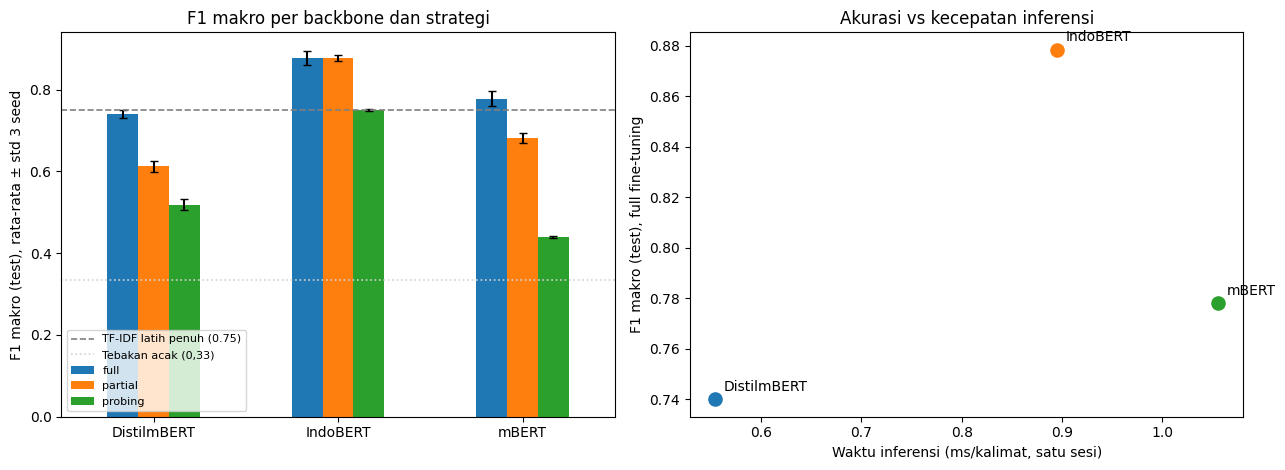

In [13]:
import matplotlib.pyplot as plt
rr = pd.read_csv(FILE_REKAP)
urut = ["full", "partial", "probing"]
piv = rr.pivot(index="backbone", columns="strategi", values="f1_test_mean")[urut]
err = rr.pivot(index="backbone", columns="strategi", values="f1_test_std")[urut]

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
piv.plot.bar(yerr=err, ax=ax[0], capsize=3, rot=0)
ax[0].axhline(f1_tfidf, color="gray", ls="--", lw=1.2, label=f"TF-IDF latih penuh ({f1_tfidf:.2f})")
ax[0].axhline(1 / 3, color="lightgray", ls=":", lw=1.2, label="Tebakan acak (0,33)")
ax[0].legend(fontsize=8)
ax[0].set_ylabel("F1 makro (test), rata-rata ± std 3 seed")
ax[0].set_title("F1 makro per backbone dan strategi")
ax[0].set_xlabel("")

f = rr[rr.strategi == "full"]
for _, x in f.iterrows():
    ms = inf.loc[x.backbone, "inferensi_ms_mean"]
    ax[1].scatter(ms, x.f1_test_mean, s=90)
    ax[1].annotate(x.backbone, (ms, x.f1_test_mean), textcoords="offset points", xytext=(6, 6))
ax[1].set_xlabel("Waktu inferensi (ms/kalimat, satu sesi)")
ax[1].set_ylabel("F1 makro (test), full fine-tuning")
ax[1].set_title("Akurasi vs kecepatan inferensi")
plt.tight_layout()
plt.savefig(f"grafik_perbandingan_{KODE}.png", dpi=150)
plt.show()